In [4]:
#%pip install transformers

In [5]:
#%pip install torch

In [3]:
#%pip install pandas numpy seaborn

In [6]:
#%pip install matplotlib scikit-learn

Sentiment Analysis Using a Pretrained Language Mode :

Introduction :

Sentiment analysis is a Natural Language Processing (NLP) task that identifies the emotional tone of text. It is widely used in product reviews, customer feedback, social media analysis, and opinion mining.

This project implements a pretrained DistilBERT model to classify English text into positive and negative sentiment categories. The project evaluates its predictions, examines confidence scores, compares predictions with labeled data, and visualizes the results.

Objectives :

- Understand the basic working of a pretrained language model.
- Implement sentiment classification using Python.
- Test the model on different text inputs.
- Evaluate model performance using standard classification metrics.
- Visualize results and investigate prediction errors.
- Identify the model's strengths, limitations, and practical applications.

In [ ]:
# importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# importing necessary libraries for sentiment analysis
from transformers import pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

d:\24DBC009\intermediate_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully!


In [ ]:
# Load the sentiment analysis model
model_name = (
    "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

sentiment_pipeline = pipeline(
    "text-classification",
    model=model_name
)

print("Sentiment analysis model loaded successfully!")

d:\24DBC009\intermediate_project\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\24DBC009\intermediate_project\.venv\Lib\site-packages\huggingface_hub\f

Sentiment analysis model loaded successfully!


In [ ]:
# Example usage of the sentiment analysis pipeline
texts = [
    "This product is excellent and works perfectly.",
    "I am disappointed with the quality.",
    "The service was wonderful.",
    "The experience was terrible.",
    "The movie was okay, but not very exciting."
]

predictions = sentiment_pipeline(texts)

for text, result in zip(texts, predictions):
    print("Text:", text)
    print("Predicted sentiment:", result["label"])
    print("Confidence:", round(result["score"], 4))
    print("-" * 50)

Text: This product is excellent and works perfectly.
Predicted sentiment: POSITIVE
Confidence: 0.9999
--------------------------------------------------
Text: I am disappointed with the quality.
Predicted sentiment: NEGATIVE
Confidence: 0.9998
--------------------------------------------------
Text: The service was wonderful.
Predicted sentiment: POSITIVE
Confidence: 0.9999
--------------------------------------------------
Text: The experience was terrible.
Predicted sentiment: NEGATIVE
Confidence: 0.9994
--------------------------------------------------
Text: The movie was okay, but not very exciting.
Predicted sentiment: NEGATIVE
Confidence: 0.9979
--------------------------------------------------


In [7]:
#%pip install datasets

In [ ]:
#%pip install -U datasets huggingface_hub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Load the SST-2 dataset from the GLUE benchmark
from datasets import load_dataset

dataset = load_dataset(
    "nyu-mll/glue",
    "sst2",
    split="validation"
)

sample = dataset.select(range(200))

test_texts = sample["sentence"]
true_labels = sample["label"]

print("Number of evaluation examples:", len(test_texts))

d:\24DBC009\intermediate_project\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\datasets--nyu-mll--glue. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Generating test split: 100%|██████████| 1821/1821 [00:00<00:00, 60372.83 examples/s]


Number of evaluation examples: 200


In [ ]:
# Check the type and content of the test texts
print(type(test_texts))
print(type(test_texts[0]))
print(repr(test_texts[0]))

<class 'datasets.arrow_dataset.Column'>
<class 'str'>
"it 's a charming and often affecting journey . "


In [ ]:
# Convert test_texts to a list
test_texts = list(test_texts)

print(type(test_texts))
print(type(test_texts[0]))
print("Number of texts:", len(test_texts))

<class 'list'>
<class 'str'>
Number of texts: 200


In [ ]:
# Perform sentiment analysis on the test texts
results = sentiment_pipeline(
    test_texts,
    batch_size=16,
    truncation=True
)

predicted_labels = [
    1 if result["label"] == "POSITIVE" else 0
    for result in results
]

print("Predictions completed:", len(predicted_labels))
print("Actual labels:", len(true_labels))

Predictions completed: 200
Actual labels: 200


In [ ]:
# Calculate evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

metrics = {
    "Accuracy": accuracy_score(true_labels, predicted_labels),
    "Precision": precision_score(
        true_labels, predicted_labels, zero_division=0
    ),
    "Recall": recall_score(
        true_labels, predicted_labels, zero_division=0
    ),
    "F1-score": f1_score(
        true_labels, predicted_labels, zero_division=0
    )
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Score"]
)

display(metrics_df)

,Metric,Score
0,Accuracy,0.910000
1,Precision,0.871560
2,Recall,0.959596
3,F1-score,0.913462


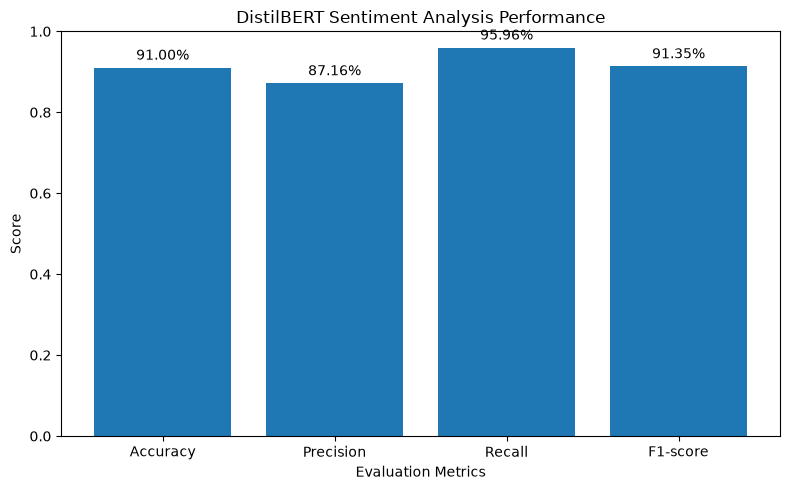

In [ ]:
# Visualize the evaluation metrics
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.title("DistilBERT Sentiment Analysis Performance")

for i, score in enumerate(metrics.values()):
    plt.text(i, score + 0.02, f"{score:.2%}", ha="center")

plt.tight_layout()
plt.show()

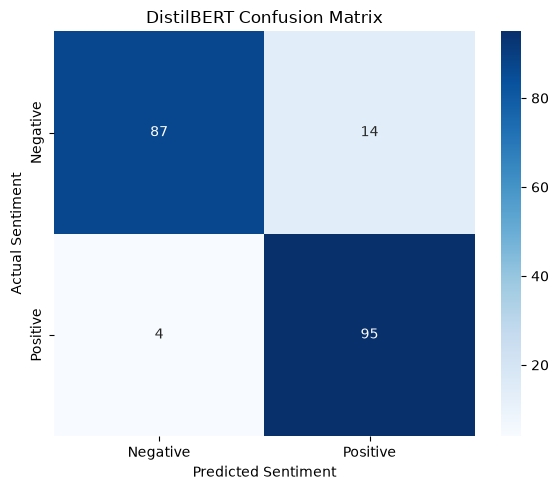

Confusion matrix:
[[87 14]
 [ 4 95]]


In [ ]:
# Visualize the confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("DistilBERT Confusion Matrix")

plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

In [16]:
from datasets import load_dataset

dataset = load_dataset(
    "nyu-mll/glue",
    "sst2",
    split="validation"
)

sample = dataset.select(range(200))

test_texts = list(sample["sentence"])
true_labels = list(sample["label"])

print("Dataset loaded:", len(test_texts))
print("Labels loaded:", len(true_labels))

d:\24DBC009\intermediate_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset loaded: 200
Labels loaded: 200


In [18]:
from transformers import pipeline

model_name = (
    "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

sentiment_pipeline = pipeline(
    "text-classification",
    model=model_name
)

print("Sentiment model loaded successfully!")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 426.79it/s]


Sentiment model loaded successfully!


In [19]:
results = sentiment_pipeline(
    test_texts,
    batch_size=16,
    truncation=True
)

predicted_labels = [
    1 if result["label"] == "POSITIVE" else 0
    for result in results
]

print("Predictions:", len(predicted_labels))
print("Results:", len(results))

Predictions: 200
Results: 200


In [20]:
evaluation_df = pd.DataFrame({
    "Text": test_texts,
    "Actual Sentiment": [
        "Positive" if label == 1 else "Negative"
        for label in true_labels
    ],
    "Predicted Sentiment": [
        "Positive" if label == 1 else "Negative"
        for label in predicted_labels
    ],
    "Confidence": [
        result["score"] for result in results
    ]
})

errors_df = evaluation_df[
    evaluation_df["Actual Sentiment"]
    != evaluation_df["Predicted Sentiment"]
]

print("Total examples:", len(evaluation_df))
print("Incorrect predictions:", len(errors_df))

display(errors_df.head(10))

Total examples: 200
Incorrect predictions: 18


,Text,Actual Sentiment,Predicted Sentiment,Confidence
22,holden caulfield did it better .,Negative,Positive,0.990752
64,"the script kicks in , and mr. hartley 's diste...",Negative,Positive,0.857643
87,jaglom ... put ( s ) the audience in the privi...,Positive,Negative,0.996092
92,"you wo n't like roger , but you will quickly r...",Negative,Positive,0.998519
93,if steven soderbergh 's ` solaris ' is a failu...,Positive,Negative,0.999392
95,this riveting world war ii moral suspense stor...,Negative,Positive,0.999312
107,what the director ca n't do is make either of ...,Negative,Positive,0.941034
115,sam mendes has become valedictorian at the sch...,Negative,Positive,0.996837
118,every nanosecond of the the new guy reminds yo...,Negative,Positive,0.987379
121,it seems to me the film is about the art of ri...,Negative,Positive,0.997744


In [22]:
import matplotlib.pyplot as plt
print("Matplotlib imported successfully!")

Matplotlib imported successfully!


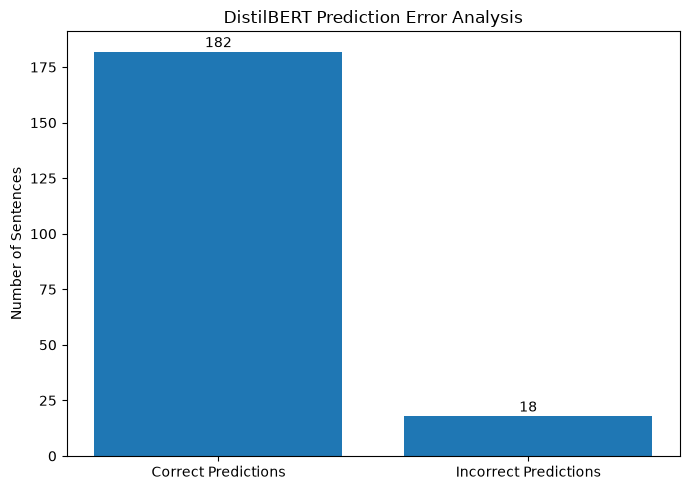

In [23]:
# Visualize correct vs incorrect predictions

correct_predictions = len(evaluation_df) - len(errors_df)
incorrect_predictions = len(errors_df)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Correct Predictions", "Incorrect Predictions"],
    [correct_predictions, incorrect_predictions]
)

plt.title("DistilBERT Prediction Error Analysis")
plt.ylabel("Number of Sentences")

for i, value in enumerate([correct_predictions, incorrect_predictions]):
    plt.text(i, value + 2, str(value), ha="center")

plt.tight_layout()
plt.show()

## Final Evaluation and Key Findings

### Model Performance
The DistilBERT sentiment analysis model was evaluated on 200 sentences from the SST-2 validation dataset.

- Total sentences evaluated: 200
- Correct predictions: 182
- Incorrect predictions: 18
- Accuracy: 91%

### Key Findings
1. The model performed well on the selected evaluation sample.
2. Some predictions were incorrect despite having high confidence scores.
3. Complex sentence structures, contextual meaning, and subtle sentiment may contribute to classification errors.
4. Confusion matrices and performance visualizations helped evaluate the model's strengths and weaknesses.

### Limitations
The model is pretrained for English sentiment classification and may struggle with sarcasm, mixed opinions, ambiguous expressions, or domain-specific language. Results from 200 examples may not represent performance on every type of text.

### Conclusion
This project demonstrated how a pretrained DistilBERT model can classify text as positive or negative. Evaluation metrics, visualizations, and error analysis provided a clearer understanding of its performance. In future work, the model could be tested on larger and more diverse datasets and compared with other sentiment analysis approaches.

EXPLORATION AND ANALYSIS

In this section, the pretrained DistilBERT model is tested on different types of sentences to examine its sentiment classification capabilities. The experiments include positive and negative statements, negation, mixed opinions, and contextual sentences. The model predictions and confidence scores are recorded to understand its strengths and limitations.

In [ ]:
# Example texts for sentiment analysis
experiment_texts = [
    "I absolutely love this product!",
    "This is the worst experience ever.",
    "The movie was not bad.",
    "The food was excellent, but the service was terrible.",
    "The laptop works well and has a great battery.",
    "I am not happy with the customer service."
]

experiment_results = sentiment_pipeline(
    experiment_texts,
    truncation=True
)

experiment_df = pd.DataFrame({
    "Input Text": experiment_texts,
    "Predicted Sentiment": [
        result["label"] for result in experiment_results
    ],
    "Confidence": [
        round(result["score"], 4)
        for result in experiment_results
    ]
})

display(experiment_df)

,Input Text,Predicted Sentiment,Confidence
0,I absolutely love this product!,POSITIVE,0.9999
1,This is the worst experience ever.,NEGATIVE,0.9998
2,The movie was not bad.,POSITIVE,0.9987
3,"The food was excellent, but the service was te...",NEGATIVE,0.9171
4,The laptop works well and has a great battery.,POSITIVE,0.9996
5,I am not happy with the customer service.,NEGATIVE,0.9998


Research Questions and Objectives

Research Questions

1. How accurately does DistilBERT classify positive and negative sentiment?
2. How does the model handle negation in sentences?
3. How does it classify sentences containing both positive and negative opinions?
4. What is the relationship between prediction confidence and prediction correctness?
5. What are the major limitations of the model?

Objectives

- To evaluate the sentiment classification performance of DistilBERT.
- To examine the model's behavior on different types of text.
- To analyze prediction confidence and classification errors.
- To identify the strengths and limitations of pretrained language models.
- To explore practical applications of NLP in customer feedback and review analysis.

## Research Questions — Answers and Findings

### 1. How accurately does DistilBERT classify positive and negative sentiment?

DistilBERT was evaluated on 200 examples from the SST-2 validation dataset. It correctly classified 182 examples and incorrectly classified 18, achieving 91% accuracy. Precision, recall, and F1-score were also calculated to provide a broader evaluation of the model's performance.

### 2. How does the model handle negation in sentences?

The model can classify many sentences containing negation, but negation may change the meaning of a sentence and lead to incorrect predictions. For example, phrases such as "not bad" can express a positive meaning despite containing a negative word. The exploratory experiments help investigate this behavior. A single example does not establish how well the model handles negation in general.

### 3. How does it classify sentences containing both positive and negative opinions?

Sentences containing mixed opinions can be challenging because the model must interpret different sentiments within the same sentence. For example, "The food was excellent, but the service was terrible" contains both positive and negative opinions. The model produces one overall sentiment label, which may not fully represent both opinions.

### 4. What is the relationship between prediction confidence and prediction correctness?

Prediction confidence represents how strongly the model favors its predicted label. The error analysis showed that some incorrect predictions had high confidence scores. Therefore, a high confidence score does not guarantee that a prediction is correct.

### 5. What are the major limitations of the model?

The model may struggle with sarcasm, negation, mixed opinions, ambiguous language, and domain-specific expressions. It produces a single positive or negative label and may not capture every detail of a sentence. Its evaluation on 200 examples also limits how broadly the results can be generalized.

In [ ]:
# Save the exploration results to a CSV file
experiment_df.to_csv(
    "exploration_results.csv",
    index=False
)

print("Exploration results saved successfully!")

Exploration results saved successfully!


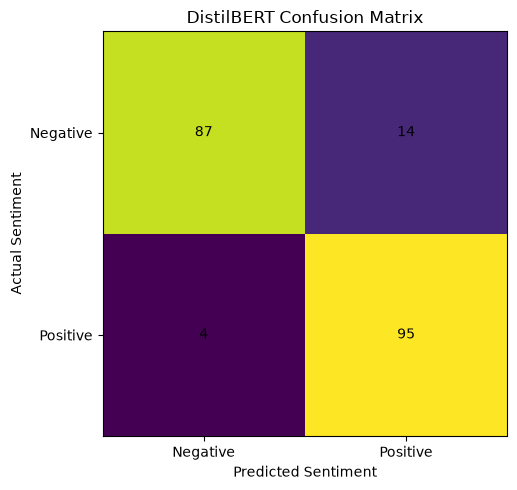

All evaluation files saved successfully!
Files: evaluation_results.csv, evaluation_metrics.csv,
       confusion_matrix.csv, confusion_matrix.png


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# 1. Save individual predictions
evaluation_df.to_csv("evaluation_results.csv", index=False)

# 2. Save evaluation metrics
metrics_df = pd.DataFrame([
    ["Accuracy", accuracy_score(true_labels, predicted_labels)],
    ["Precision", precision_score(true_labels, predicted_labels, zero_division=0)],
    ["Recall", recall_score(true_labels, predicted_labels, zero_division=0)],
    ["F1-score", f1_score(true_labels, predicted_labels, zero_division=0)]
], columns=["Metric", "Score"])

metrics_df.to_csv("evaluation_metrics.csv", index=False)

# 3. Save confusion matrix
cm = confusion_matrix(true_labels, predicted_labels, labels=[0, 1])

cm_df = pd.DataFrame(
    cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
)
cm_df.to_csv("confusion_matrix.csv")

# 4. Save confusion matrix image
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("DistilBERT Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("All evaluation files saved successfully!")
print("Files: evaluation_results.csv, evaluation_metrics.csv,")
print("       confusion_matrix.csv, confusion_matrix.png")

## Conclusion

In this project, I implemented sentiment analysis using a pretrained DistilBERT model from Hugging Face Transformers. The model classified English text into positive and negative sentiments.

The model was evaluated on 200 examples from the SST-2 validation dataset and achieved 91% accuracy, correctly classifying 182 examples and incorrectly classifying 18 examples.

Accuracy, precision, recall, F1-score, a confusion matrix, and visualizations were used to evaluate the model. Error analysis also showed that a high confidence score does not always guarantee a correct prediction.

This project helped me understand transformer-based NLP models, sentiment classification, model evaluation, data visualization, and error analysis. Future improvements could include testing on larger datasets and evaluating performance on sarcasm, mixed sentiments, and domain-specific text.